# 30. CN7 unlabeled — 날짜별 '온도 교란 언덕 수' vs '일별 불량 수(ERR_FACT_QTY)'

**언덕 기준 = 29번 그대로**: 구간 점수 E ≥ 정상 기준 95% 분위수(오경보 5%), 재가동 후 15샷 제외, 연속 경보 = 언덕 1개
**불량 수**: `ERR_FACT_QTY` (생산계획일 × LH/RH) 합계 → 샷도 같은 **생산계획일(PART_FACT_PLAN_DATE)** 기준으로 묶음
**비교용**: 같은 날 최종 모델 경보(pct ≥ 0.999) 수

⚠ 주의
- 기록된 샷이 몇 개뿐인데 불량 수는 큰 날이 많음 → **생산 샷 300개 이상인 날만** 비교
- ERR_FACT_QTY는 가스 외 유형도 섞인 합계일 수 있음 → '관련성' 수준 해석
- 비교 가능한 날짜 수가 적으면(10개 안팎) 상관이 우연일 수 있음 → 순열 p 함께 확인

In [1]:
import os
import pandas as pd
from daily_check import build, correlations, plot, MIN_SHOTS
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30); pd.set_option('display.max_rows', 100)
OUT = './outputs/daily_check'
os.makedirs(OUT, exist_ok=True)

D, F, INFO = build('cn7')
D.to_csv(f'{OUT}/cn7_daily.csv', index=False, encoding='utf-8-sig')
print(INFO)

{'임계값 E': 3.146343887888244, '정상기준 hopper_slope20 중앙값': np.float64(0.0023308270676691517), 'IQR': np.float64(0.02793233082706751)}


## 1. 날짜별 표 (전체)

In [2]:
cols = ['날짜', '기록_샷', '영모드_비율', '생산_샷', '불량_LH', '불량_RH', '불량_합계', '불량률(불량/(생산샷×2))',
        '언덕_수', '1000샷당_언덕', '최종모델_경보', '1000샷당_최종경보', '금형온도_중앙', '호퍼온도_중앙', 'labeled 기간', '비교 대상']
display(D[[c for c in cols if c in D.columns]].round(3))
print('비교 대상 날짜 수:', int(D['비교 대상'].sum()))

C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_26004\2590419867.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(D[[c for c in cols if c in D.columns]].round(3))


,날짜,기록_샷,영모드_비율,생산_샷,불량_LH,불량_RH,불량_합계,불량률(불량/(생산샷×2)),언덕_수,1000샷당_언덕,최종모델_경보,1000샷당_최종경보,금형온도_중앙,호퍼온도_중앙,labeled 기간,비교 대상
0,2020-03-24,8,0.000,8,NaN,321.0,321.0,20.062,0.0,0.000,0.0,0.000,19.80,58.60,False,False
1,2020-04-01,1065,0.919,86,96.0,154.0,250.0,1.453,0.0,0.000,0.0,0.000,22.25,59.00,False,False
2,2020-04-03,16,0.000,16,118.0,75.0,193.0,6.031,0.0,0.000,0.0,0.000,22.65,58.45,False,False
3,2020-04-04,1198,0.000,1198,NaN,17.0,17.0,0.007,6.0,5.008,16.0,13.356,21.70,35.00,False,True
4,2020-04-06,1,0.000,1,188.0,15.0,203.0,101.500,0.0,0.000,0.0,0.000,22.70,58.70,False,False
5,2020-05-27,590,0.000,590,NaN,2.0,2.0,0.002,15.0,25.424,24.0,40.678,24.40,60.00,False,True
6,2020-05-28,390,0.997,1,3.0,NaN,3.0,1.500,0.0,0.000,0.0,0.000,27.60,59.10,False,False
7,2020-07-24,107,0.477,56,50.0,50.0,100.0,0.893,0.0,0.000,0.0,0.000,28.20,66.95,False,False
8,2020-07-28,12,0.000,12,31.0,NaN,31.0,1.292,0.0,0.000,0.0,0.000,23.40,37.45,False,False
9,2020-07-29,478,0.000,478,15.0,0.0,15.0,0.016,3.0,6.276,0.0,0.000,31.30,60.00,False,True


비교 대상 날짜 수: 11


## 2. 상관 (비교 대상 날짜만, Spearman + 순열 p)
- **1000샷당 언덕 ↔ 불량률 ρ > 0 이고 순열 p < 0.05** → 온도 교란이 잦은 날 불량도 많음 = 주의 알림 근거 강화
- 최종 모델 경보와도 비교: 최종 모델은 미성형형 이상을 잡으므로 다른 패턴일 수 있음

In [3]:
CR = correlations(D); CR.to_csv(f'{OUT}/cn7_daily_corr.csv', index=False, encoding='utf-8-sig')
display(CR.round(3))

,x (날짜별),y (날짜별),날짜 수,Spearman ρ,순열 p
0,1000샷당_언덕,불량_합계,11,-0.318,0.340
1,1000샷당_언덕,불량률(불량/(생산샷×2)),11,-0.436,0.187
2,언덕_수,불량_합계,11,0.073,0.840
3,언덕_수,불량률(불량/(생산샷×2)),11,-0.303,0.360
4,1000샷당_최종경보,불량_합계,11,-0.326,0.328
5,1000샷당_최종경보,불량률(불량/(생산샷×2)),11,-0.391,0.235
6,금형온도_중앙,불량_합계,11,0.200,0.552
7,금형온도_중앙,불량률(불량/(생산샷×2)),11,0.401,0.219
8,호퍼온도_중앙,불량_합계,11,-0.164,0.625
9,호퍼온도_중앙,불량률(불량/(생산샷×2)),11,-0.169,0.622


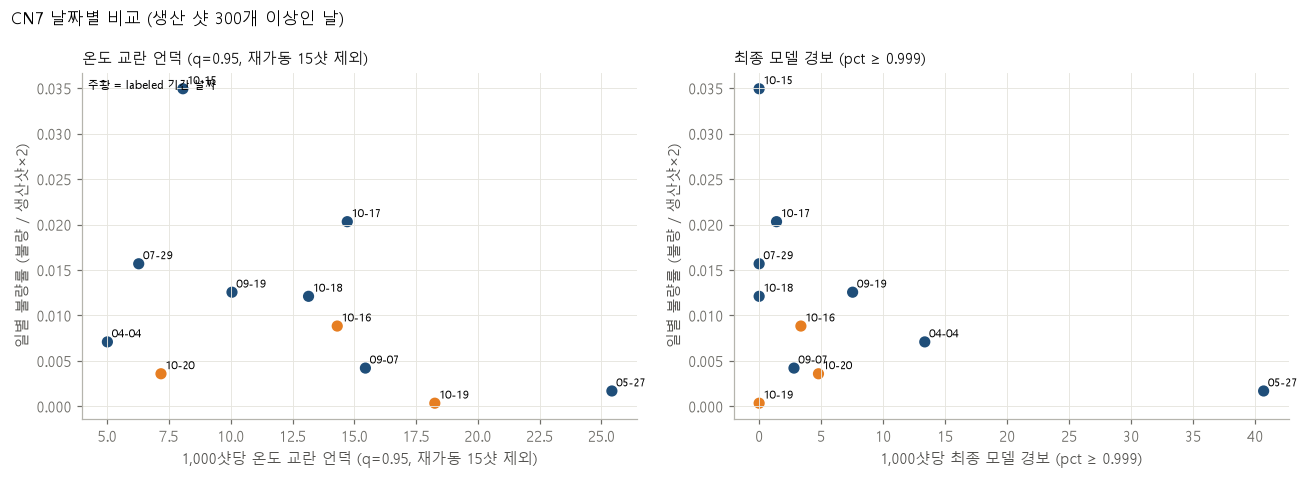

In [4]:
plot(D, save=f'{OUT}/cn7_daily_scatter.png')

## 해석 가이드
| 결과 | 판단 |
|---|---|
| 언덕 ↔ 불량률 ρ 양수·유의, 금형/호퍼 수준과는 무관 | 온도 '수준'이 아니라 '교란'이 불량과 관련 → 4장 주의 알림 근거 |
| ρ ≈ 0 또는 음수 | 날짜 단위로는 관련성 확인 안 됨 → R1 한 번의 현상, 가설로만 |
| 날짜 수가 너무 적음(< 8) 또는 한두 날짜가 결과를 좌우 | 판단 보류 (그래프에서 날짜별 위치 확인) |